
# EduReason AI

## Explainable Hybrid AI for Student Success Prediction

### Project Objective

The goal of this project is to build an intelligent academic decision-support system that combines Machine Learning, Explainable AI, and Symbolic Reasoning.

The system will predict student academic outcomes and provide understandable explanations and recommendations.

### Project Workflow

1. Data Collection
2. Data Cleaning and Exploration
3. Feature Engineering
4. Machine Learning Model Development
5. Explainable AI using SHAP
6. Symbolic Reasoning
7. Hybrid AI Integration
8. Model Evaluation
9. Interactive Dashboard


In [2]:
#import the libraries required for our project

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
print("Edureason-AI libraries are ready")

Edureason-AI libraries are ready


In [4]:

# Check the versions of our installed libraries

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version:", sns.__version__)

import sklearn
print("Scikit-learn version:", sklearn.__version__)


NumPy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2
Seaborn version: 0.13.2
Scikit-learn version: 1.9.1


In [5]:

# Import Pandas
import pandas as pd

# Define the path to our dataset
file_path = "../data/raw/data.csv"

# Load the dataset
df = pd.read_csv(file_path, sep=";")

# Display a success message
print("Dataset loaded successfully!")



Dataset loaded successfully!


In [6]:

# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display the first five records
display(df.head())


Dataset dimensions: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [7]:

# Display all column names
print("Columns in our dataset:\n")

for column in df.columns:
    print(column)


Columns in our dataset:

Marital status
Application mode
Application order
Course
Daytime/evening attendance	
Previous qualification
Previous qualification (grade)
Nacionality
Mother's qualification
Father's qualification
Mother's occupation
Father's occupation
Admission grade
Displaced
Educational special needs
Debtor
Tuition fees up to date
Gender
Scholarship holder
Age at enrollment
International
Curricular units 1st sem (credited)
Curricular units 1st sem (enrolled)
Curricular units 1st sem (evaluations)
Curricular units 1st sem (approved)
Curricular units 1st sem (grade)
Curricular units 1st sem (without evaluations)
Curricular units 2nd sem (credited)
Curricular units 2nd sem (enrolled)
Curricular units 2nd sem (evaluations)
Curricular units 2nd sem (approved)
Curricular units 2nd sem (grade)
Curricular units 2nd sem (without evaluations)
Unemployment rate
Inflation rate
GDP
Target


In [8]:

# Display column names with their index numbers

for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")


1. Marital status
2. Application mode
3. Application order
4. Course
5. Daytime/evening attendance	
6. Previous qualification
7. Previous qualification (grade)
8. Nacionality
9. Mother's qualification
10. Father's qualification
11. Mother's occupation
12. Father's occupation
13. Admission grade
14. Displaced
15. Educational special needs
16. Debtor
17. Tuition fees up to date
18. Gender
19. Scholarship holder
20. Age at enrollment
21. International
22. Curricular units 1st sem (credited)
23. Curricular units 1st sem (enrolled)
24. Curricular units 1st sem (evaluations)
25. Curricular units 1st sem (approved)
26. Curricular units 1st sem (grade)
27. Curricular units 1st sem (without evaluations)
28. Curricular units 2nd sem (credited)
29. Curricular units 2nd sem (enrolled)
30. Curricular units 2nd sem (evaluations)
31. Curricular units 2nd sem (approved)
32. Curricular units 2nd sem (grade)
33. Curricular units 2nd sem (without evaluations)
34. Unemployment rate
35. Inflation rate
36. 

In [10]:

# Display the different academic outcomes

print(df["Target"].value_counts())


Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [12]:

# Count missing values in every column

missing_values = df.isnull().sum()

print(missing_values)


Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [13]:

# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [14]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [15]:
#generate descriptinve statistics for numerical columns

In [16]:

# Analyse student age

print("Average age:", df["Age at enrollment"].mean())
print("Median age:", df["Age at enrollment"].median())
print("Minimum age:", df["Age at enrollment"].min())
print("Maximum age:", df["Age at enrollment"].max())


Average age: 23.265144665461122
Median age: 20.0
Minimum age: 17
Maximum age: 70


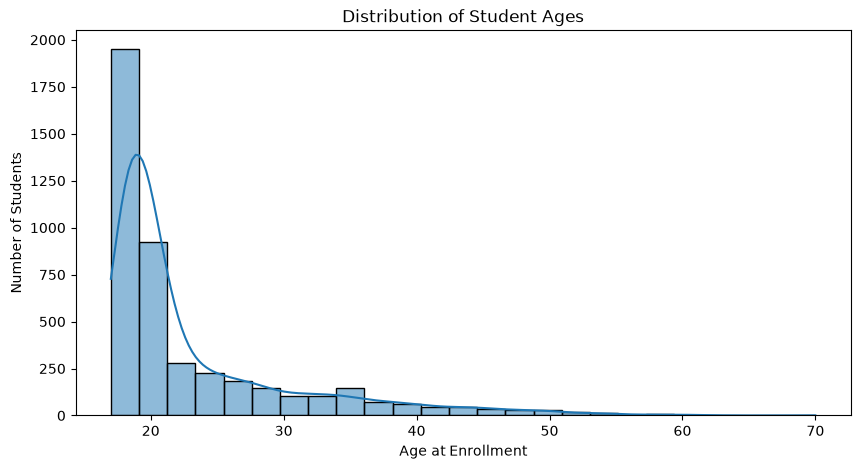

In [17]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age at enrollment",
    bins=25,
    kde=True
)

plt.title("Distribution of Student Ages")
plt.xlabel("Age at Enrollment")
plt.ylabel("Number of Students")

plt.show()


In [18]:

# Calculate average age for each academic outcome

average_age = df.groupby("Target")["Age at enrollment"].mean()

print(average_age)


Target
Dropout     26.068966
Enrolled    22.369018
Graduate    21.783612
Name: Age at enrollment, dtype: float64


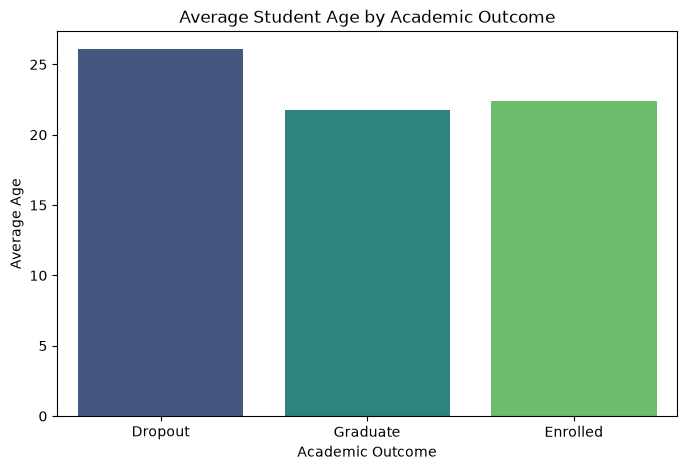

In [19]:

# Compare average student age across academic outcomes

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Target",
    y="Age at enrollment",
    hue="Target",
    palette="viridis",
    errorbar=None
)

plt.title("Average Student Age by Academic Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("Average Age")

plt.show()


In [20]:

# Calculate academic outcome percentages by age group

df["Age Group"] = pd.cut(
    df["Age at enrollment"],
    bins=[16, 20, 25, 30, 40, 50, 100],
    labels=["17-20", "21-25", "26-30", "31-40", "41-50", "Above 50"]
)

age_outcome = pd.crosstab(
    df["Age Group"],
    df["Target"],
    normalize="index"
) * 100

print(age_outcome.round(2))


Target     Dropout  Enrolled  Graduate
Age Group                             
17-20        21.25     18.46     60.29
21-25        35.63     21.98     42.39
26-30        59.79     14.88     25.33
31-40        55.15     13.27     31.58
41-50        50.55     13.19     36.26
Above 50     51.16      4.65     44.19


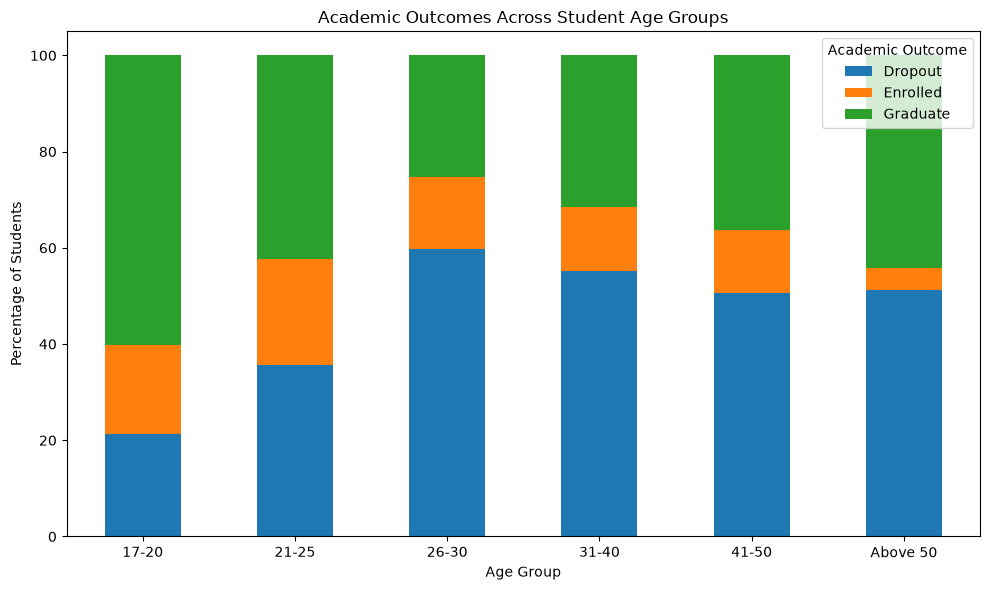

In [21]:

# Visualise academic outcomes across age groups

age_outcome.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Academic Outcomes Across Student Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Students")
plt.legend(title="Academic Outcome")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [22]:

# Select academic performance variables

academic_features = [
    "Previous qualification (grade)",
    "Admission grade",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)"
]

# Calculate correlations
correlation_matrix = df[academic_features].corr()

# Display correlation values
display(correlation_matrix.round(2))


,Previous qualification (grade),Admission grade,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
Previous qualification (grade),1.00,0.58,-0.03,0.05,0.06,-0.03,0.05,0.05
Admission grade,0.58,1.00,-0.03,0.07,0.07,-0.04,0.08,0.07
Curricular units 1st sem (enrolled),-0.03,-0.03,1.00,0.77,0.38,0.94,0.67,0.36
Curricular units 1st sem (approved),0.05,0.07,0.77,1.00,0.70,0.73,0.90,0.69
Curricular units 1st sem (grade),0.06,0.07,0.38,0.70,1.00,0.41,0.67,0.84
Curricular units 2nd sem (enrolled),-0.03,-0.04,0.94,0.73,0.41,1.00,0.70,0.40
Curricular units 2nd sem (approved),0.05,0.08,0.67,0.90,0.67,0.70,1.00,0.76
Curricular units 2nd sem (grade),0.05,0.07,0.36,0.69,0.84,0.40,0.76,1.00


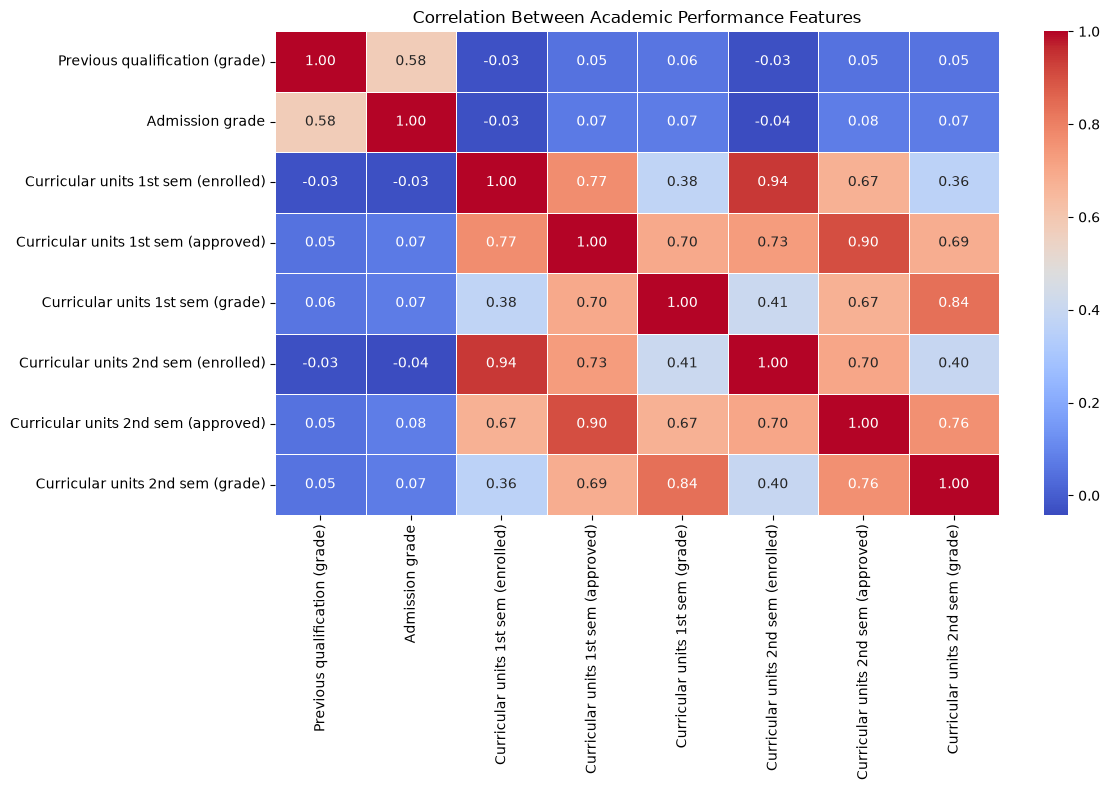

In [23]:

# Create a correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Academic Performance Features")
plt.tight_layout()
plt.show()


In [24]:

# Compare first-semester approved units across outcomes

approved_by_outcome = df.groupby("Target")[
    "Curricular units 1st sem (approved)"
].mean()

print(approved_by_outcome)


Target
Dropout     2.551724
Enrolled    4.318640
Graduate    6.232232
Name: Curricular units 1st sem (approved), dtype: float64


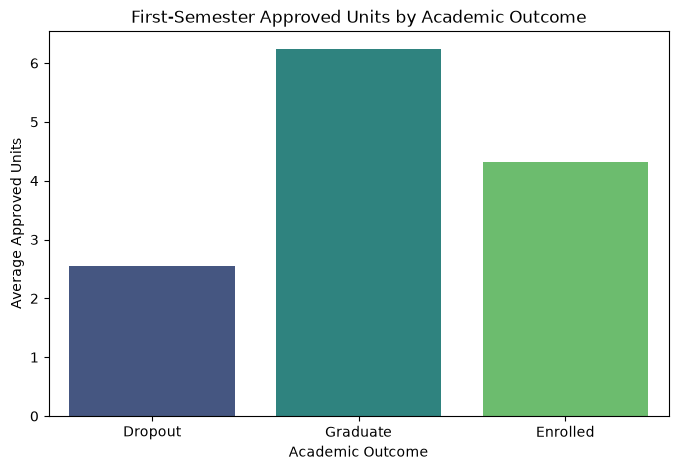

In [25]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (approved)",
    hue="Target",
    palette="viridis",
    errorbar=None
)

plt.title("First-Semester Approved Units by Academic Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("Average Approved Units")

plt.show()


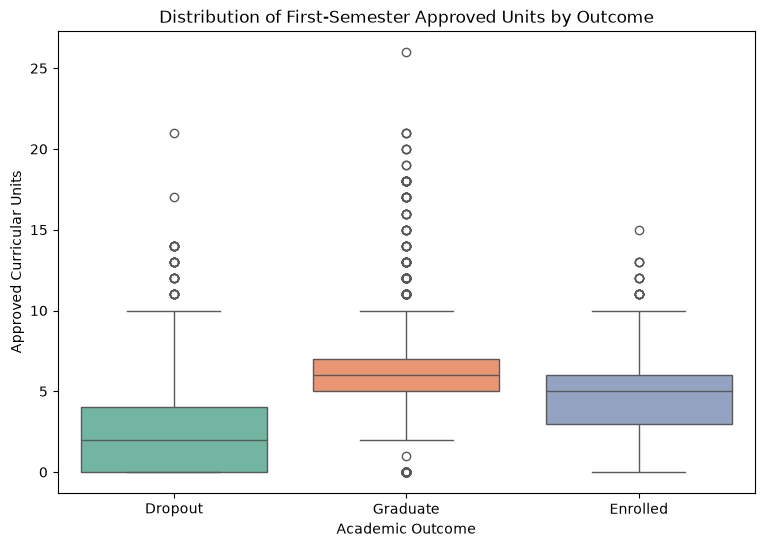

In [26]:

# Compare first-semester approved units across outcomes

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (approved)",
    hue="Target",
    palette="Set2",
    legend=False
)

plt.title("Distribution of First-Semester Approved Units by Outcome")
plt.xlabel("Academic Outcome")
plt.ylabel("Approved Curricular Units")

plt.show()



## Initial Exploratory Data Analysis - Findings

### 1. Dataset Overview
- Total records: 4,424
- Total columns: 37
- Input features: 36
- Target variable: Target
- Target classes: Dropout, Enrolled, Graduate

### 2. Data Quality
- Missing values: 0
- Duplicate rows: 0

### 3. Target Distribution
- Graduate: 2,209
- Dropout: 1,421
- Enrolled: 794

### 4. Age Analysis
- Average age: 23.27
- Median age: 20
- Minimum age: 17
- Maximum age: 70
- Age distribution is right-skewed.

### 5. Academic Performance Analysis
- Average first-semester approved units:
  - Dropout: 2.55
  - Enrolled: 4.32
  - Graduate: 6.23

- First-semester approved units show a noticeable difference across academic outcomes.
- First-semester and second-semester academic performance variables show strong positive correlations.

### 6. Initial Insights
1. Age is associated with academic outcomes.
2. Younger age groups have higher graduation percentages in this dataset.
3. Students who graduate tend to approve more first-semester curricular units.
4. First-semester academic performance may provide useful early-warning signals.

### 7. Next Steps
- Perform additional data-quality checks.
- Define early-prediction features.
- Prevent data leakage.
- Build baseline Machine Learning models.
- Evaluate performance across all three classes.
